# Sepsis Early Warning: end-to-end analysis

**Question:** can a model trained on hourly vitals and labs warn of sepsis earlier than **NEWS2**, the NHS early-warning score, **without more false alarms**?

This notebook uses a 1,500-patient cohort so it runs in about a minute. `python -m sepsis.train` runs the full 4,000-patient evaluation reported in the README.

**Contents**
1. Setup
2. Data structure: one row per patient-hour
3. Data quality and missingness
4. Descriptive statistics
5. Patient-level view: stays, sepsis prevalence
6. Vital-sign distributions: septic vs non-septic
7. What deterioration looks like before onset
8. NEWS2 and qSOFA baselines
9. Feature engineering (past-only)
10. Model training with a patient-level split
11. Row-level evaluation
12. Alert-level evaluation: what the ward experiences
13. Lead time
14. Interpretation and the lab-ordering question
15. Conclusions

## 1. Setup

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
from sepsis.data import generate_cohort, VITALS, LABS
from sepsis.features import make_features, feature_columns
from sepsis.alerts import evaluate_alerts, threshold_for_burden, burden_curve, alert_hours
from sepsis.train import patient_split, build_model
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.3f}".format)

## 2. Data structure

In [2]:
raw = generate_cohort(n_patients=1500, seed=3)
print(f"{len(raw):,} patient-hours from {raw.patient_id.nunique():,} patients")
raw.head(10)

128,329 patient-hours from 1,500 patients

,patient_id,hour,age,copd,postop,hr,resp_rate,temp,sbp,spo2,wbc,lactate,creatinine,platelets,map,on_oxygen,alert,sepsis_onset_hour,label
0,0,0,70,0,0,56.000,20.000,36.500,139.000,97.000,6.700,1.200,138.600,184.400,95.000,0,1,109.000,0
1,0,1,70,0,0,70.000,22.000,36.600,149.000,98.000,NaN,NaN,NaN,NaN,97.000,0,1,109.000,0
2,0,2,70,0,0,65.000,29.000,36.700,140.000,98.000,NaN,NaN,NaN,NaN,91.000,0,1,109.000,0
3,0,3,70,0,0,68.000,22.000,36.300,139.000,95.000,NaN,NaN,NaN,NaN,104.000,0,1,109.000,0
4,0,4,70,0,0,59.000,25.000,36.400,149.000,95.000,NaN,NaN,NaN,NaN,98.000,0,1,109.000,0
5,0,5,70,0,0,69.000,22.000,37.000,154.000,96.000,NaN,NaN,NaN,NaN,104.000,0,1,109.000,0
6,0,6,70,0,0,69.000,23.000,36.300,153.000,97.000,NaN,NaN,NaN,NaN,100.000,0,1,109.000,0
7,0,7,70,0,0,66.000,23.000,36.500,149.000,95.000,NaN,NaN,NaN,NaN,101.000,0,1,109.000,0
8,0,8,70,0,0,62.000,24.000,36.800,152.000,97.000,NaN,NaN,NaN,NaN,100.000,0,1,109.000,0
9,0,9,70,0,0,71.000,26.000,36.900,133.000,97.000,NaN,NaN,NaN,NaN,92.000,0,1,109.000,0


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 128329 entries, 0 to 128328
Data columns (total 19 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   patient_id         128329 non-null  int64  
 1   hour               128329 non-null  int64  
 2   age                128329 non-null  int64  
 3   copd               128329 non-null  int64  
 4   postop             128329 non-null  int64  
 5   hr                 128329 non-null  float64
 6   resp_rate          128329 non-null  float64
 7   temp               128329 non-null  float64
 8   sbp                128329 non-null  float64
 9   spo2               128329 non-null  float64
 10  wbc                9586 non-null    float64
 11  lactate            9586 non-null    float64
 12  creatinine         9586 non-null    float64
 13  platelets          9586 non-null    float64
 14  map                128329 non-null  float64
 15  on_oxygen          128329 non-null  int64  
 16  alert        

| Column | Meaning |
|---|---|
| `hr`, `resp_rate`, `temp`, `sbp`, `map`, `spo2` | hourly vital signs |
| `on_oxygen`, `alert` | supplemental oxygen; alert (1) vs new confusion/drowsiness (0) |
| `wbc`, `lactate`, `creatinine`, `platelets` | lab results, **only present when drawn** |
| `age`, `copd`, `postop` | patient context |
| `sepsis_onset_hour` | when sepsis was recognised (empty if never) |
| `label` | **target**: sepsis onset within the next 6 hours |

## 3. Data quality and missingness

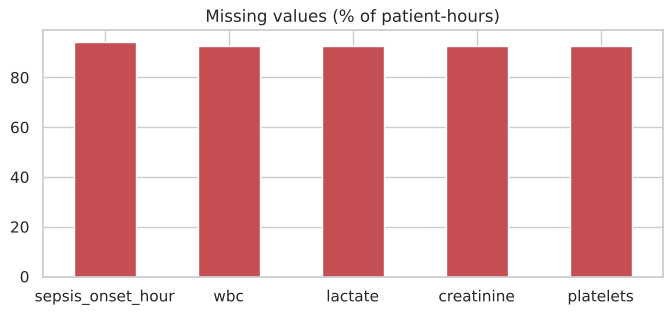

,sepsis_onset_hour,wbc,lactate,creatinine,platelets,patient_id,hour,age,copd,hr,postop,spo2,sbp,temp,resp_rate,map,on_oxygen,alert,label
missing %,94.300,92.500,92.500,92.500,92.500,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


In [4]:
miss = raw.isna().mean().mul(100).sort_values(ascending=False)
miss[miss > 0].plot.bar(figsize=(8, 3.2), rot=0, color="#c44e52", title="Missing values (% of patient-hours)"); miss.round(1).to_frame("missing %").T

Labs are missing ~90% of hours, as on a real ward where bloods are taken every 6–24 hours. Missingness is informative, so the features record when each lab was last measured.

In [5]:
print("Duplicate patient-hours:", raw.duplicated(["patient_id", "hour"]).sum())
print("Physiologically impossible SpO2 (>100):", (raw.spo2 > 100).sum())
print("Heart rate range:", raw.hr.min(), "–", raw.hr.max())

Duplicate patient-hours: 0
Physiologically impossible SpO2 (>100): 0
Heart rate range: 30.0 – 173.0

## 4. Descriptive statistics

In [6]:
raw[VITALS + LABS + ['age']].describe().T

,count,mean,std,min,25%,50%,75%,max
hr,"128,329.000",83.944,13.768,30.000,75.000,83.000,92.000,173.000
resp_rate,"128,329.000",17.392,3.796,1.000,15.000,17.000,20.000,41.000
temp,"128,329.000",36.956,0.548,34.900,36.600,36.900,37.300,41.200
sbp,"128,329.000",124.243,18.828,33.000,112.000,124.000,137.000,209.000
map,"128,329.000",86.327,11.083,36.000,79.000,86.000,94.000,138.000
spo2,"128,329.000",95.987,2.158,85.000,95.000,96.000,97.000,100.000
wbc,"9,586.000",8.558,2.371,-0.300,7.000,8.600,10.200,17.900
lactate,"9,586.000",1.205,0.432,0.300,0.900,1.200,1.500,4.000
creatinine,"9,586.000",85.214,25.961,1.400,67.700,84.600,102.500,238.000
platelets,"9,586.000",239.986,62.048,0.700,198.600,239.800,282.000,459.400


## 5. Patient-level view

Septic patients: 9.7%  | positive-label hours: 0.79%

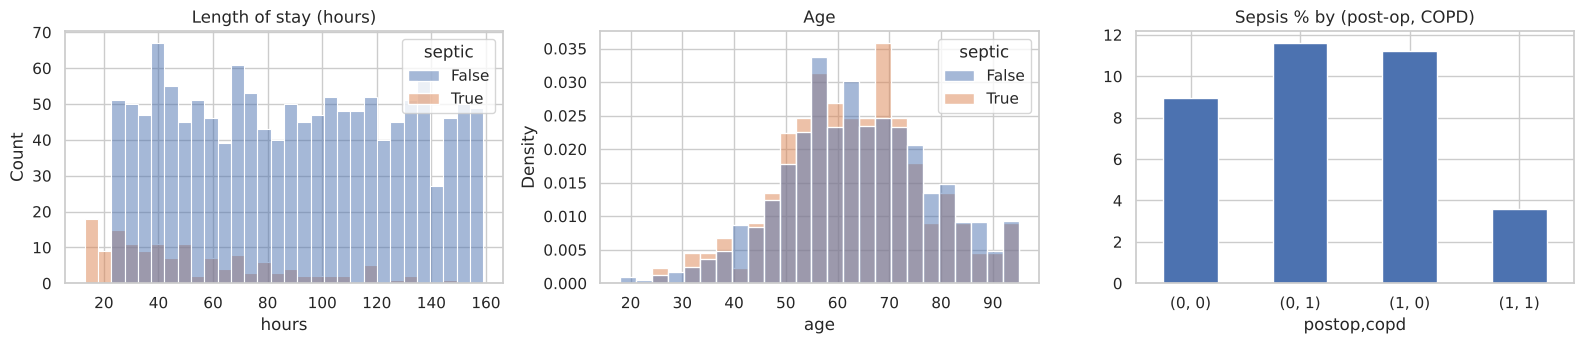

In [7]:
pts = raw.groupby("patient_id").agg(hours=("hour", "size"), septic=("sepsis_onset_hour", lambda s: s.notna().any()),
                                    age=("age", "first"), copd=("copd", "first"), postop=("postop", "first"))
print(f"Septic patients: {pts.septic.mean():.1%}  | positive-label hours: {raw.label.mean():.2%}")
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
sns.histplot(data=pts, x="hours", hue="septic", bins=30, ax=axes[0]); axes[0].set_title("Length of stay (hours)")
sns.histplot(data=pts, x="age", hue="septic", bins=25, ax=axes[1], stat="density", common_norm=False); axes[1].set_title("Age")
pts.groupby(["postop", "copd"]).septic.mean().mul(100).plot.bar(ax=axes[2], rot=0, title="Sepsis % by (post-op, COPD)")
plt.tight_layout()

## 6. Vital signs: septic vs non-septic hours

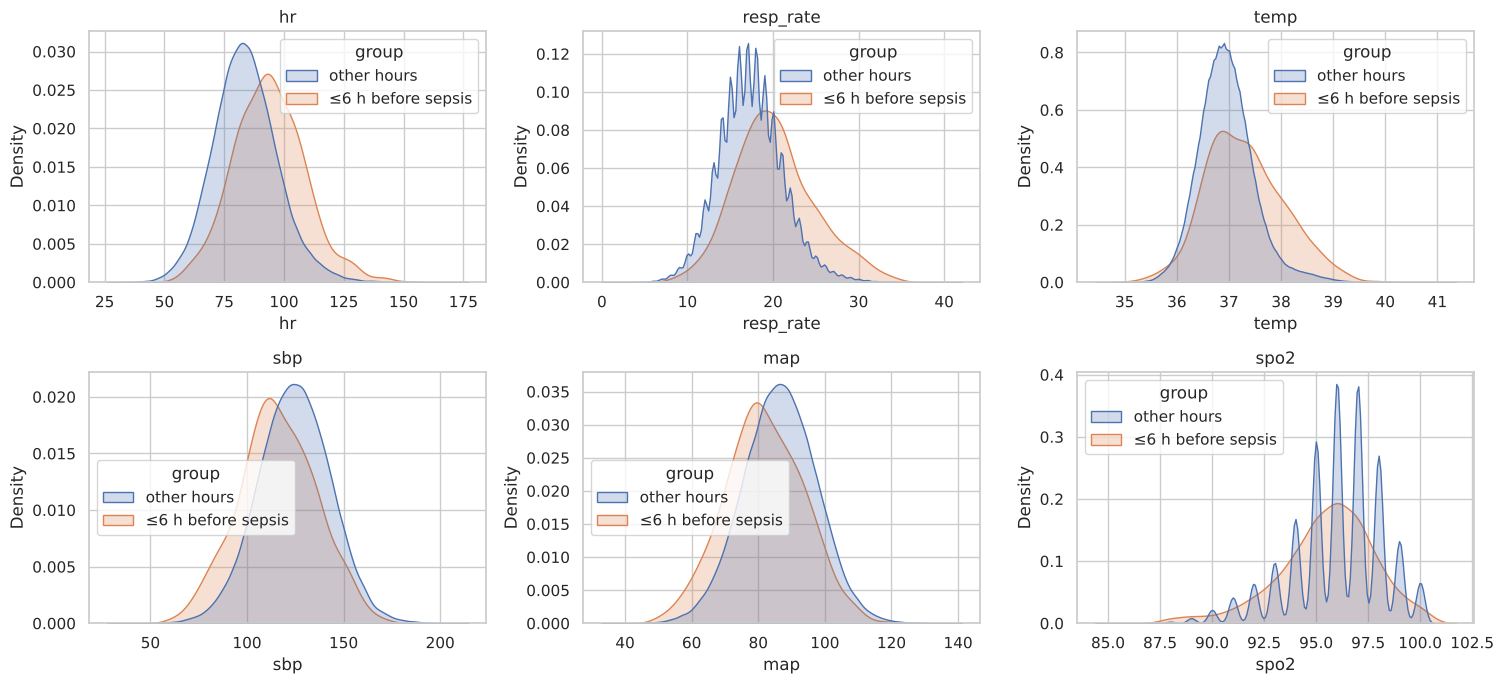

In [8]:
lab = raw.assign(group=np.where(raw.label == 1, "≤6 h before sepsis", "other hours"))
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, v in zip(axes.ravel(), VITALS):
    sns.kdeplot(data=lab, x=v, hue="group", common_norm=False, fill=True, ax=ax); ax.set_title(v)
plt.tight_layout()

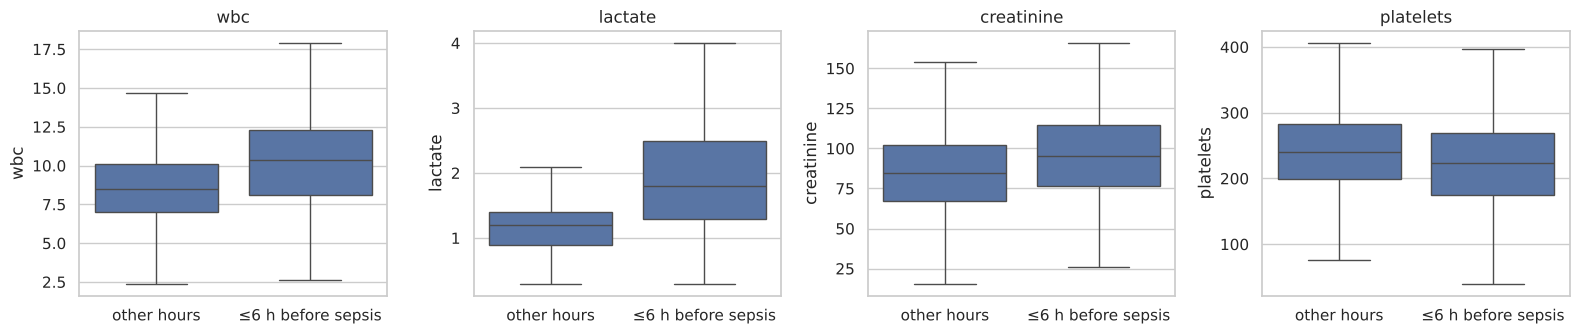

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, v in zip(axes, LABS):
    sns.boxplot(data=lab.dropna(subset=[v]), x="group", y=v, ax=ax, showfliers=False); ax.set_title(v); ax.set_xlabel("")
plt.tight_layout()

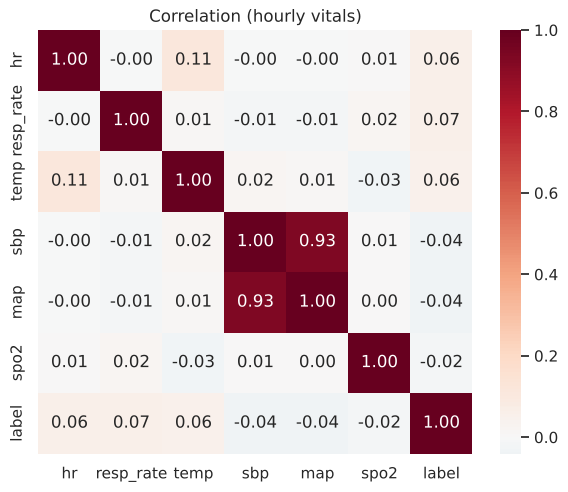

In [10]:
corr = raw[VITALS + ["label"]].corr()
plt.figure(figsize=(7, 5.5)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0); plt.title("Correlation (hourly vitals)");

## 7. What deterioration looks like
Average trajectories aligned on the hour of onset (septic patients only).

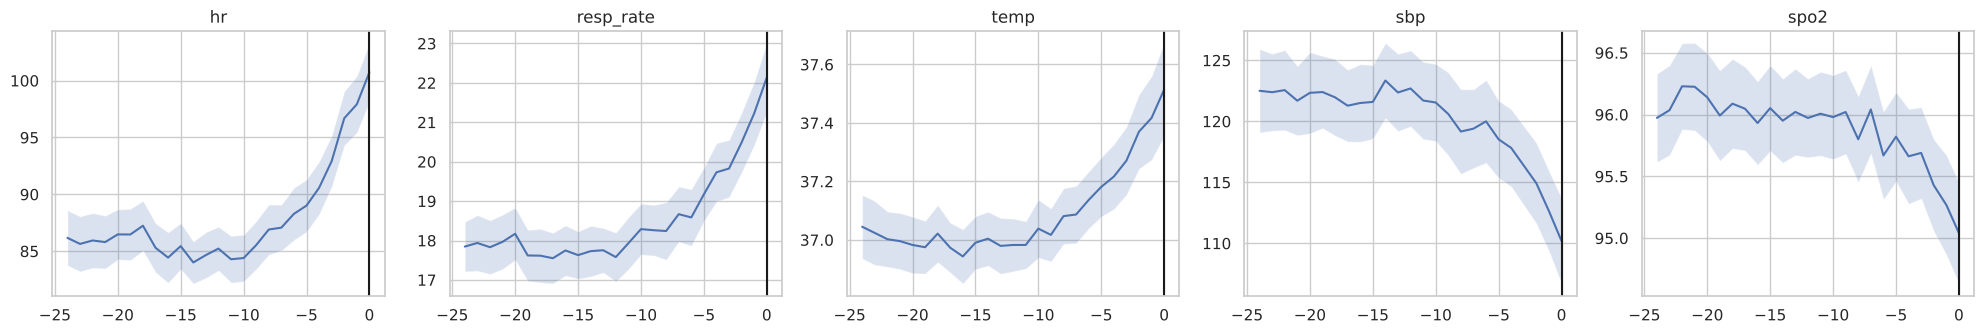

In [11]:
sep = raw[raw.sepsis_onset_hour.notna()].assign(h=lambda d: d.hour - d.sepsis_onset_hour)
aligned = sep[sep.h >= -24].groupby("h")[["hr", "resp_rate", "temp", "sbp", "spo2"]].agg(["mean", "sem"])
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, v in zip(axes, ["hr", "resp_rate", "temp", "sbp", "spo2"]):
    m, se = aligned[(v, "mean")], aligned[(v, "sem")]
    ax.plot(m.index, m); ax.fill_between(m.index, m - 2 * se, m + 2 * se, alpha=0.2); ax.axvline(0, c="k"); ax.set_title(v)
plt.tight_layout()

Deterioration starts several hours before onset, but **gradually and differently for each patient** (not everyone develops a fever or low blood pressure). That is why single-threshold scores struggle.

## 8. NEWS2 and qSOFA baselines

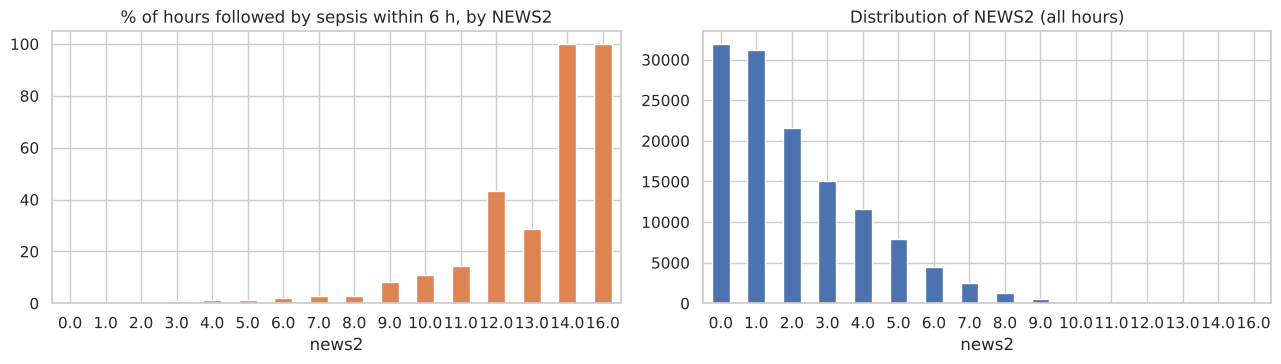

In [12]:
feat = make_features(raw)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
feat.groupby("news2").label.mean().mul(100).plot.bar(ax=axes[0], rot=0, color="#dd8452", title="% of hours followed by sepsis within 6 h, by NEWS2")
feat.news2.value_counts().sort_index().plot.bar(ax=axes[1], rot=0, title="Distribution of NEWS2 (all hours)")
plt.tight_layout()

## 9. Feature engineering
Every feature uses only the past: rolling 6-hour stats, change over 6 hours, deviation from the patient's own first-6-hour baseline, last lab values and time since measured.

In [13]:
cols = feature_columns(feat)
print(len(cols), "features"); pd.Series(cols).str.extract(r"_(mean6|max6|min6|delta6|vs_baseline|last|measured|hours_since|n_draws_24h)$")[0].fillna("raw / score").value_counts()

64 features

,count
0,
raw / score,16
max6,7
delta6,7
mean6,6
min6,6
vs_baseline,6
measured,4
last,4
hours_since,4


In [14]:
feat.loc[feat.patient_id == sep.patient_id.iloc[0], ["hour", "hr", "hr_mean6", "hr_delta6", "hr_vs_baseline", "lactate", "lactate_last", "lactate_hours_since", "news2", "label"]].tail(10)

,hour,hr,hr_mean6,hr_delta6,hr_vs_baseline,lactate,lactate_last,lactate_hours_since,news2,label
100,100,88.000,93.000,-14.000,23.500,NaN,1.300,22.000,0.000,0
101,101,81.000,90.667,-14.000,16.500,NaN,1.300,23.000,0.000,0
102,102,76.000,86.833,-23.000,11.500,0.900,0.900,0.000,2.000,0
103,103,74.000,82.333,-27.000,9.500,NaN,0.900,1.000,0.000,1
104,104,63.000,75.833,-39.000,-1.500,NaN,0.900,2.000,0.000,1
105,105,70.000,75.333,-3.000,5.500,NaN,0.900,3.000,0.000,1
106,106,82.000,74.333,-6.000,17.500,1.200,1.200,0.000,0.000,1
107,107,94.000,76.500,13.000,29.500,NaN,1.200,1.000,1.000,1
108,108,83.000,77.667,7.000,18.500,1.200,1.200,0.000,6.000,1
109,109,96.000,81.333,22.000,31.500,1.100,1.100,0.000,4.000,1


## 10. Training with a patient-level split
No patient appears in both training and test data.

In [15]:
train, test = patient_split(feat)
print(f"train patients {train.patient_id.nunique()}, test patients {test.patient_id.nunique()}, overlap {len(set(train.patient_id) & set(test.patient_id))}")
model = build_model().fit(train[cols], train["label"])
test = test.assign(model_risk=model.predict_proba(test[cols])[:, 1])

train patients 1050, test patients 450, overlap 0

## 11. Row-level evaluation

In [16]:
scores = {"ML model": test.model_risk, "NEWS2": test.news2, "qSOFA": test.qsofa}
pd.DataFrame({k: {"AUROC": roc_auc_score(test.label, v), "AUPRC": average_precision_score(test.label, v)} for k, v in scores.items()}).T

,AUROC,AUPRC
ML model,0.795,0.270
NEWS2,0.653,0.013
qSOFA,0.620,0.014


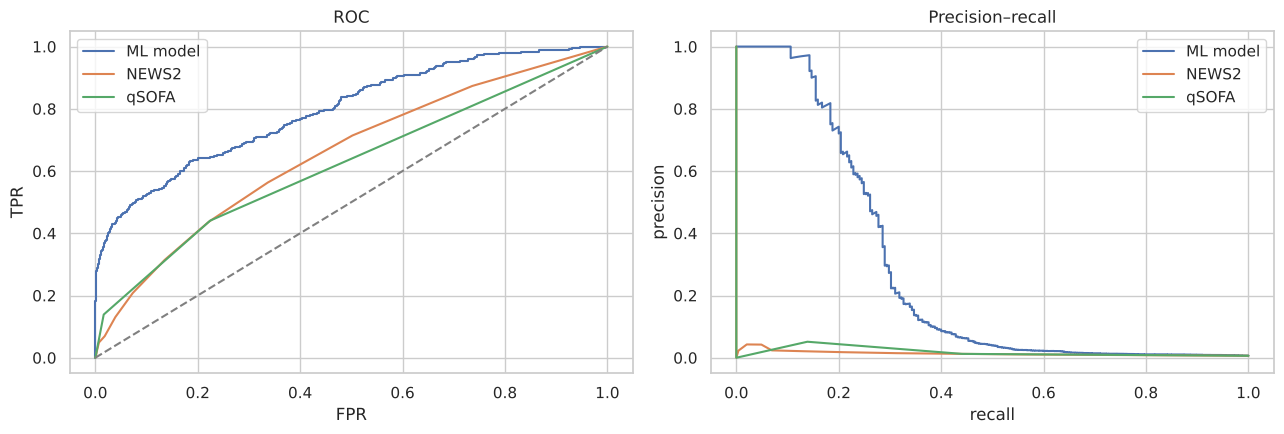

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for k, v in scores.items():
    f, t, _ = roc_curve(test.label, v); axes[0].plot(f, t, label=k)
    p, r, _ = precision_recall_curve(test.label, v); axes[1].plot(r, p, label=k)
axes[0].plot([0, 1], [0, 1], "--", c="grey"); axes[0].set(title="ROC", xlabel="FPR", ylabel="TPR")
axes[1].set(title="Precision–recall", xlabel="recall", ylabel="precision")
for a in axes: a.legend()
plt.tight_layout()

## 12. Alert-level evaluation
An alert fires when the score crosses its threshold, then stays silent for 6 h. A septic patient is *caught* if alerted in the 12 h before onset. Everything else is a false alarm.

In [18]:
news7 = evaluate_alerts(test, "news2", 7)
news5 = evaluate_alerts(test, "news2", 5)
t7 = threshold_for_burden(test, "model_risk", news7["false_alarms_per_100_patient_days"])
t5 = threshold_for_burden(test, "model_risk", news5["false_alarms_per_100_patient_days"])
pd.DataFrame({"NEWS2 ≥ 7": news7, "ML @ NEWS2≥7 alarm rate": evaluate_alerts(test, "model_risk", t7),
              "NEWS2 ≥ 5": news5, "ML @ NEWS2≥5 alarm rate": evaluate_alerts(test, "model_risk", t5),
              "qSOFA ≥ 2": evaluate_alerts(test, "qsofa", 2)}).T

,threshold,sensitivity,median_lead_time_h,false_alarms_per_100_patient_days,ppv_of_alerts,septic_patients
NEWS2 ≥ 7,7.000,0.543,2.000,36.000,0.032,35.000
ML @ NEWS2≥7 alarm rate,0.019,0.943,2.000,35.800,0.054,35.000
NEWS2 ≥ 5,5.000,0.800,2.000,98.100,0.017,35.000
ML @ NEWS2≥5 alarm rate,0.005,1.000,4.000,97.500,0.022,35.000
qSOFA ≥ 2,2.000,0.571,2.000,20.800,0.056,35.000


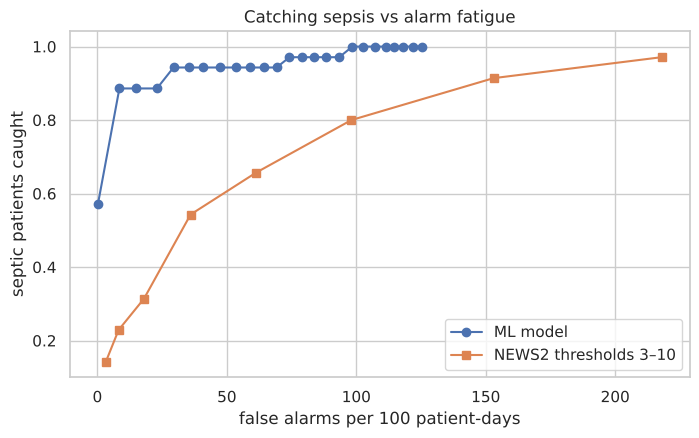

In [19]:
mc = burden_curve(test, "model_risk", np.unique(np.quantile(test.model_risk, np.linspace(0.85, 0.999, 25))))
nc = burden_curve(test, "news2", range(3, 11))
plt.figure(figsize=(8, 4.5))
plt.plot(mc.false_alarms_per_100_patient_days, mc.sensitivity, marker="o", label="ML model")
plt.plot(nc.false_alarms_per_100_patient_days, nc.sensitivity, marker="s", label="NEWS2 thresholds 3–10")
plt.xlabel("false alarms per 100 patient-days"); plt.ylabel("septic patients caught"); plt.title("Catching sepsis vs alarm fatigue"); plt.legend();

## 13. Lead time

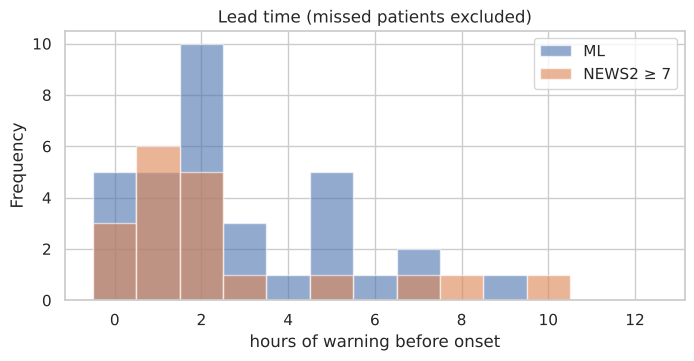

,count,mean,std,min,25%,50%,75%,max
ML,33.000,2.788,2.315,0.000,1.000,2.000,5.000,9.000
NEWS2 ≥ 7,19.000,2.579,2.854,0.000,1.000,2.000,2.500,10.000


In [20]:
leads = {"ML": [], "NEWS2 ≥ 7": []}
for pid, p in test[test.sepsis_onset_hour.notna()].groupby("patient_id"):
    onset = p.sepsis_onset_hour.iloc[0]
    for name, col, t in [("ML", "model_risk", t7), ("NEWS2 ≥ 7", "news2", 7)]:
        a = [h for h in alert_hours(p.hour.to_numpy(), p[col].to_numpy(), t) if onset - 12 <= h <= onset]
        leads[name].append(onset - a[0] if a else np.nan)
lead = pd.DataFrame(leads)
fig, ax = plt.subplots(figsize=(8, 3.5))
lead.plot.hist(bins=np.arange(-0.5, 13.5, 1), alpha=0.6, ax=ax); ax.set(xlabel="hours of warning before onset", title="Lead time (missed patients excluded)")
lead.describe().T

## 14. Interpretation and the lab-ordering question

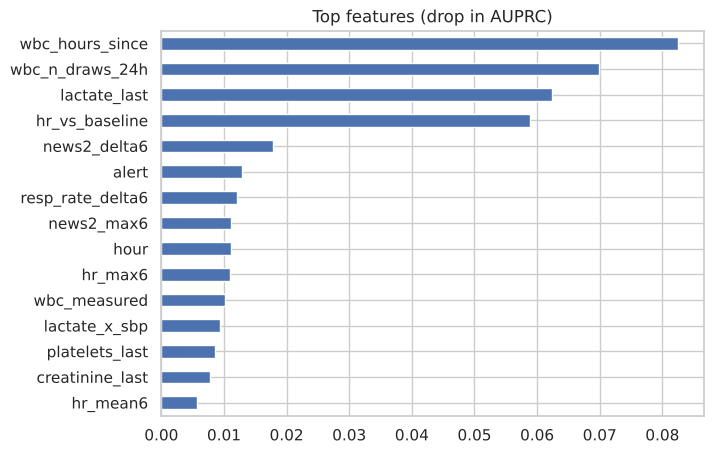

In [21]:
from sklearn.inspection import permutation_importance
sample = test.sample(15000, random_state=0)
imp = permutation_importance(model, sample[cols], sample.label, scoring="average_precision", n_repeats=3, random_state=0)
pd.Series(imp.importances_mean, index=cols).sort_values().tail(15).plot.barh(figsize=(7, 5), color="#4c72b0", title="Top features (drop in AUPRC)");

Features about **when labs were ordered** rank highly. Clinicians order bloods when they're already worried, so these features partly encode existing suspicion. Retraining without them checks how much of the signal is physiology:

In [22]:
process = [c for c in cols if c.endswith(("_measured", "_hours_since", "_n_draws_24h"))]
physio = [c for c in cols if c not in process]
m2 = build_model().fit(train[physio], train.label)
test["physio_risk"] = m2.predict_proba(test[physio])[:, 1]
tp = threshold_for_burden(test, "physio_risk", news7["false_alarms_per_100_patient_days"])
pd.DataFrame({"full model": {"AUROC": roc_auc_score(test.label, test.model_risk), "caught @ NEWS2≥7 rate": evaluate_alerts(test, "model_risk", t7)["sensitivity"]},
              "physiology only": {"AUROC": roc_auc_score(test.label, test.physio_risk), "caught @ NEWS2≥7 rate": evaluate_alerts(test, "physio_risk", tp)["sensitivity"]}}).T

,AUROC,caught @ NEWS2≥7 rate
full model,0.795,0.943
physiology only,0.791,0.857


## 15. Conclusions
- Sepsis deterioration is gradual and heterogeneous, so single-threshold scores trade sensitivity for alarms.
- At **matched false-alarm rates**, the ML model catches far more septic patients than NEWS2 (94% vs 54% here), with similar warning time (median 2 h). The extra catches are patients NEWS2 never flags at all.
- Most of the benefit survives without lab-ordering features, so the model isn't simply echoing the care team.
- Real deployment would need external validation, silent-mode trials and clinical safety governance (DCB0129/0160).